# PIVC Phlebitis — Data Cleaning & EDA

**Goal:** turn the raw nursing-observation extract into an analysis-ready table with **one row per peripheral IV cannula (PIVC)**, then explore which factors are associated with phlebitis.

**Inputs** (`data/`)
- `incubator3_data.csv` — 6.4M rows, long format: one row per nursing entry (insert / in-situ check / removal) per cannula slot, with patient demographics & Charlson comorbidities repeated on every row.
- `incubator3_skin and mobility.csv` — one nursing admission assessment (skin + Braden mobility) per admission, keyed by `Case_No_Masked` = `VisitNo_Masked`.

**Key cleaning decisions** (each justified below)
1. **Unit of analysis = one cannula**, not one row. `phlebitis_event = 1` is only set on the *removal* row, so row-level modelling is wrong.
2. `Set A–D` are reusable *slots* within an admission. A physical cannula = a run of rows in one (admission, slot), split at each **Inserted** row and after each **Removed** row.
3. Event time = `TimeColumn`, falling back to `EnteredDataDtm`. The dictionary says "ignore if NA", but those rows contain **~23% of all phlebitis events**.
4. Leakage: `Event`, `RemovedReason`, `Phlebitis`, `Episode`, `Cum Days`, `max_set`, `set_category` describe what happened *after* insertion; they must not be used as predictors of a score computed at insertion.

The data is 2.8 GB, so we use **DuckDB** (SQL directly on the file) and cache to Parquet.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'
OUT = DATA / 'processed'
OUT.mkdir(exist_ok=True)
RAW_CSV = DATA / 'incubator3_data.csv'
SKIN_CSV = DATA / 'incubator3_skin and mobility.csv'
RAW_PQ = DATA / 'raw_main.parquet'

con = duckdb.connect()
q = lambda sql: con.sql(sql).df()

pd.set_option('display.max_columns', 60, 'display.width', 200)
BLUE, GREY, INK, MUTED = '#2a78d6', '#8a8984', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.grid': True, 'grid.color': '#ecebe7', 'axes.axisbelow': True})

## 1. Load raw data (cache CSV → Parquet once)

In [2]:
if not RAW_PQ.exists():
    # all_varchar: the CSV has a stray repeated header row mid-file, which breaks type sniffing
    con.execute(f"COPY (SELECT * FROM read_csv('{RAW_CSV}', all_varchar=true, header=true)) "
                f"TO '{RAW_PQ}' (FORMAT parquet, COMPRESSION zstd)")
con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM '{RAW_PQ}'")
con.execute(f"CREATE OR REPLACE VIEW skin_raw AS SELECT * FROM read_csv('{SKIN_CSV}', all_varchar=true, header=true)")
q("SELECT count(*) AS rows, count(DISTINCT VisitNo_Masked) AS admissions, count(DISTINCT NRIC_Masked) AS patients FROM raw")

,rows,admissions,patients
0,6437060,417194,179785


### 1a. Raw missingness
Compare with the data dictionary. Note: **there is no Gender or BMI column** in this extract, although the project deck lists them, so they need to be requested. Mobility & skin come from the second file.

In [3]:
cols = [c for c in q("DESCRIBE raw")['column_name']]
miss = q("SELECT " + ", ".join(f'avg(("{c}" IS NULL)::int) AS "{c}"' for c in cols) + " FROM raw").T
miss.columns = ['pct_missing']
(miss['pct_missing'] * 100).round(1).sort_values(ascending=False).to_frame().T

,ServiceCode,Episode,DateInserted,DischargeDtm,event_date,TimeColumn,Event,antecubital,RemovedReason,other_location,Loc IB,adm_12mths,Loc MB,Peripheral_Vascular_Disease,immunocompromised,Dementia,Rheumatoid_Connective_Tissue_Disease,Congestive_Heart_Failure,Cerebrovascular_Disease,Acute_Myocardial_Infarction,cci,Age,Peptic_Ulcer,Diabetes_simple,Chronic_Pulmonary_Disease,Malignancy,Diabetes_complicated,Liver_Disease_mild,Paraplegia_hemiplegia,Renal_Disease,Metastatic_Solid_Tumour,Liver_Disease_moderate_severe,hiv_aids,AdmitDtm,NRIC_Masked,Name_Masked,sets_on_day,concurrent_sets,set_category,max_set,phlebitis_event,ward,Cum Days,Loc Ins,Days event after adm,New set?,Phlebitis,TouchedWhen,EnteredDataDtm,PeripheralIVCannulaSet,VisitNo_Masked
pct_missing,94.7,84.1,54.9,24.1,18.0,18.0,5.8,5.8,5.8,5.8,1.9,1.6,1.6,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 1b. Quirks found in the raw file

In [4]:
print('Stray header rows:', q("SELECT count(*) n FROM raw WHERE PeripheralIVCannulaSet = 'PeripheralIVCannulaSet'").n[0])
print('Age sentinel 999:', q("SELECT count(DISTINCT VisitNo_Masked) n FROM raw WHERE try_cast(Age AS double) >= 120").n[0], 'admissions')
print('Exact duplicate rows:', q("SELECT (SELECT count(*) FROM raw) - (SELECT count(*) FROM (SELECT DISTINCT * FROM raw)) n").n[0])
q('''SELECT TimeColumn IS NULL AS time_missing, count(*) AS rows, sum(phlebitis_event::int) AS phlebitis_rows
     FROM raw GROUP BY 1''')

Stray header rows: 1
Age sentinel 999: 6 admissions


Exact duplicate rows: 215721


,time_missing,rows,phlebitis_rows
0,True,1158991,6474.0
1,False,5278069,21242.0


## 2. Row-level cleaning
- drop stray header row, **exact duplicate rows** (~3%), and rows with no `Event` (no observation recorded)
- `t` = `TimeColumn` else `EnteredDataDtm`
- `kind`: 2 = Inserted, 1 = Removed, 0 = in-situ check
- normalise en-dash vs hyphen in `Event` text; parse insertion **site** and **side**
- `Age` 999 → NULL

In [5]:
con.execute(r'''
CREATE OR REPLACE TABLE obs AS
SELECT
  VisitNo_Masked AS visit, NRIC_Masked AS patient,
  regexp_extract(PeripheralIVCannulaSet, 'Set ([A-D])', 1) AS slot,
  coalesce(try_strptime(TimeColumn, '%Y-%m-%dT%H:%M:%SZ'),
           try_strptime(EnteredDataDtm, '%Y-%m-%dT%H:%M:%SZ')) AS t,
  try_strptime(EnteredDataDtm, '%Y-%m-%dT%H:%M:%SZ') AS t_entered,
  replace(Event, '–', '-') AS event,
  CASE WHEN RemovedReason = 'Inserte' THEN 2 WHEN Event ILIKE 'Removed%' THEN 1 ELSE 0 END AS kind,
  phlebitis_event::int AS phleb,
  "Loc Ins" AS loc_ins, ward, antecubital,
  try_cast("Cum Days" AS double) AS cum_days,
  try_strptime(AdmitDtm, '%Y-%m-%dT%H:%M:%SZ') AS admit_t,
  try_strptime(DischargeDtm, '%Y-%m-%dT%H:%M:%SZ') AS discharge_t,
  ServiceCode AS service,
  nullif(try_cast(Age AS double), 999) AS age,
  try_cast(adm_12mths AS double) AS adm_12mths,
  try_cast(cci AS double) AS cci,
  * EXCLUDE (Name_Masked, NRIC_Masked, VisitNo_Masked, PeripheralIVCannulaSet, TimeColumn, EnteredDataDtm,
             TouchedWhen, Event, RemovedReason, Phlebitis, phlebitis_event, "Loc Ins", ward, antecubital,
             "Cum Days", AdmitDtm, DischargeDtm, ServiceCode, Age, adm_12mths, cci, DateInserted,
             "Loc MB", "Loc IB", Episode, "New set?", "Days event after adm", other_location,
             max_set, set_category, event_date, sets_on_day, concurrent_sets)
FROM (SELECT DISTINCT * FROM raw)
WHERE PeripheralIVCannulaSet <> 'PeripheralIVCannulaSet' AND Event IS NOT NULL
''')
q("SELECT kind, count(*) AS rows, sum(phleb) AS phlebitis FROM obs GROUP BY 1 ORDER BY 1")

,kind,rows,phlebitis
0,0,4603726,54.0
1,1,721681,26861.0
2,2,531187,0.0


## 3. Build the cannula-level table
Within each (admission, slot), order rows by time; a new cannula starts at an **Inserted** row, or at an in-situ row that follows a **Removed** row (cannula inserted but insertion not documented).
A Removed row straight after another Removed row is a duplicate entry for the same cannula, not a new one.
Ties at the same timestamp: Removed (old cannula) → Inserted (new) → in-situ. The order is fixed once (`ord`) so both window passes agree.

In [6]:
con.execute('''
CREATE OR REPLACE TABLE obs_seg AS
WITH o AS (
  SELECT *, row_number() OVER (PARTITION BY visit, slot
                               ORDER BY t, kind = 1 DESC, kind = 2 DESC, t_entered, event, ward) AS ord
  FROM obs
), o2 AS (
  SELECT *, coalesce(lag(kind) OVER (PARTITION BY visit, slot ORDER BY ord), -1) AS prev_kind FROM o
)
SELECT *, sum((kind = 2 OR (prev_kind = 1 AND kind = 0))::int) OVER (
            PARTITION BY visit, slot ORDER BY ord ROWS UNBOUNDED PRECEDING) AS seg
FROM o2
''')

comorb = ['Acute_Myocardial_Infarction','Cerebrovascular_Disease','Congestive_Heart_Failure',
          'Rheumatoid_Connective_Tissue_Disease','Dementia','Diabetes_simple','Liver_Disease_mild','Peptic_Ulcer',
          'Peripheral_Vascular_Disease','Chronic_Pulmonary_Disease','Malignancy','Diabetes_complicated',
          'Paraplegia_hemiplegia','Renal_Disease','Metastatic_Solid_Tumour','Liver_Disease_moderate_severe',
          'hiv_aids','immunocompromised']
comorb_sql = ',\n  '.join(f'max(try_cast({c} AS double))::int AS {c.lower()}' for c in comorb)

con.execute(fr'''
CREATE OR REPLACE TABLE cannula AS
SELECT
  visit, slot, seg, any_value(patient) AS patient,
  bool_or(kind = 2) AS has_insert, bool_or(kind = 1) AS has_removal,
  min(t) AS t_start, max(t) AS t_end,
  -- outcome
  max(phleb) AS phlebitis,
  -- "Others" removals that mention a phlebitis sign, excluding negations like "nil redness"
  max((kind = 1 AND regexp_matches(event, '(?i)removed - others.*(swel|swollen|pain|\bred\b|redness|tender|hard)')
              AND NOT regexp_matches(event, '(?i)\b(nil|no|not|without)\b'))::int) AS possible_phlebitis,
  arg_max(event, t) FILTER (WHERE kind = 1) AS removal_text,
  max(cum_days) AS dwell_days,
  -- at insertion (first row of segment)
  arg_min(loc_ins, t) AS loc_insert, arg_min(ward, t) AS ward_insert, arg_min(service, t) AS service_insert,
  arg_min(event, t) AS first_event,
  arg_min(antecubital, t) AS antecubital_raw,
  -- patient / admission (constant within admission)
  any_value(admit_t) AS admit_t, any_value(discharge_t) AS discharge_t,
  any_value(age) AS age, any_value(adm_12mths) AS adm_12mths, any_value(cci) AS cci,
  {comorb_sql}
FROM obs_seg
GROUP BY visit, slot, seg
''')

# site / side / gauge from the insertion text
con.execute(r'''
CREATE OR REPLACE TABLE cannula AS
SELECT *,
  CASE WHEN regexp_matches(first_event, '(?i)antecubital|elbow') THEN 'Antecubital'
       WHEN regexp_matches(first_event, '(?i)hand|wrist|thumb|finger') THEN 'Hand/wrist'
       WHEN regexp_matches(first_event, '(?i)arm') THEN 'Forearm/arm'
       WHEN regexp_matches(first_event, '(?i)foot|leg|ankle|toe') THEN 'Lower limb'
       WHEN regexp_matches(first_event, '(?i)neck|scalp|jugular') THEN 'Other'
       ELSE NULL END AS site,
  regexp_extract(first_event, '(?i)\b(left|right)\b', 1) AS side_raw,
  try_cast(regexp_extract(first_event, '(?i)(?:g\s*(1[468]|2[024])|(1[468]|2[024])\s*g)\b', ['a','b'])['a'] AS int) AS _g1,
  try_cast(regexp_extract(first_event, '(?i)(?:g\s*(1[468]|2[024])|(1[468]|2[024])\s*g)\b', ['a','b'])['b'] AS int) AS _g2
FROM cannula
''')
con.execute('''
CREATE OR REPLACE TABLE cannula AS
SELECT * EXCLUDE (_g1, _g2, side_raw, first_event, site), coalesce(_g1, _g2) AS gauge,
       CASE WHEN has_insert THEN upper(left(side_raw, 1)) || lower(substr(side_raw, 2)) END AS side,
       CASE WHEN has_insert THEN site END AS site_insert
FROM cannula
''')
q('''SELECT has_insert, has_removal, count(*) AS cannulas, sum(phlebitis) AS phlebitis,
            round(100*avg(phlebitis), 2) AS pct_phlebitis FROM cannula GROUP BY ALL ORDER BY ALL''')

,has_insert,has_removal,cannulas,phlebitis,pct_phlebitis
0,False,False,89489,30.0,0.03
1,False,True,294756,10958.0,3.72
2,True,False,107286,13.0,0.01
3,True,True,423901,15847.0,3.74


**Reading this table**
- **Insert + Removal** = complete record → cleanest outcome. **This is the proposed primary modelling cohort.**
- **Removal only** = cannula already in place when the record starts (e.g. inserted before the extract window / undocumented). No insertion-time features.
- **Insert only** = never documented as removed (discharged with line, or record ends). Outcome unknown → *censored*, not "no phlebitis".
- **Neither** = in-situ check fragments, mostly artefacts.

### 3a. Derived history features (only information available *before* insertion)
- `prior_cannulas_adm`: cannulas started earlier in this admission
- `prior_phleb_adm`: phlebitis already removed earlier in this admission
- `concurrent_lines`: other cannulas in place at the moment of insertion
- `prior_phleb_hx`: phlebitis in any **previous admission** of the same patient (deck: "History of IV phlebitis"); left-censored at 2017

In [7]:
con.execute('''
CREATE OR REPLACE TABLE hist AS
SELECT a.visit, a.slot, a.seg,
  count(b.seg) FILTER (WHERE b.t_start < a.t_start) AS prior_cannulas_adm,
  coalesce(sum(b.phlebitis) FILTER (WHERE b.t_end < a.t_start), 0) AS prior_phleb_adm,
  count(b.seg) FILTER (WHERE b.t_start <= a.t_start AND b.t_end > a.t_start) AS concurrent_lines
FROM cannula a LEFT JOIN cannula b
  ON a.visit = b.visit AND NOT (a.slot = b.slot AND a.seg = b.seg)
GROUP BY ALL
''')
con.execute('''
CREATE OR REPLACE TABLE visit_hx AS
SELECT visit, sum(v_phleb) OVER w - v_phleb AS prior_phleb_hx,
       count(*) OVER w - 1 AS prior_admissions_in_data
FROM (SELECT visit, any_value(patient) AS patient, min(coalesce(admit_t, t_start)) AS adm, max(phlebitis) AS v_phleb
      FROM cannula GROUP BY visit)
WINDOW w AS (PARTITION BY patient ORDER BY adm ROWS UNBOUNDED PRECEDING)
''')

## 4. Skin & mobility (admission nursing assessment)
One row per admission. We keep the timing so we can check it happened **before** the cannula was inserted (otherwise it can't be used at insertion).

In [8]:
con.execute(r'''
CREATE OR REPLACE TABLE skin AS
SELECT Case_No_Masked AS visit,
  strptime(Authored_datetime, '%d/%m/%Y %H:%M') AS skin_t,
  CASE WHEN CGH_NUR_NA_SkinColor ILIKE '%normal%' AND CGH_NUR_NA_SkinColor NOT LIKE '%,%' THEN 'Normal'
       WHEN CGH_NUR_NA_SkinColor IS NULL THEN NULL ELSE 'Abnormal' END AS skin_colour,
  CGH_NUR_NA_SkinIntegrity AS skin_integrity,
  (CGH_NUR_NA_Skin_Blister IS NOT NULL)::int AS skin_blister,
  (CGH_NUR_NA_Skin_BrokenSkin IS NOT NULL)::int AS skin_broken,
  (CGH_NUR_NA_Skin_Bruises IS NOT NULL)::int AS skin_bruises,
  (CGH_NUR_NA_Skin_Rashes IS NOT NULL)::int AS skin_rashes,
  (CGH_NUR_NA_Skin_Redness IS NOT NULL)::int AS skin_redness,
  -- bruising documented on the upper limbs (where cannulas go)
  regexp_matches(coalesce(CGH_NUR_NA_Skin_Bruises,''), '(?i)arm|hand|limb|forearm|wrist|antecubital')::int AS bruise_upper_limb,
  SHS_NUR_Assmt_Mobility AS mobility,
  try_cast(SHS_NUR_Assmt_Mobility_NUM AS int) AS mobility_score  -- Braden: 1 immobile .. 4 no limitation
FROM skin_raw
''')
q("SELECT skin_integrity, mobility, count(*) n FROM skin GROUP BY ALL ORDER BY n DESC LIMIT 12")

,skin_integrity,mobility,n
0,Intact,No Limitations,111805
1,Impaired,Slightly Limited,97318
2,Impaired,No Limitations,48742
3,Intact,Slightly Limited,42882
4,Impaired,Very Limited,28965
5,Impaired,Completely Immobile,8716
6,Intact,Very Limited,2891
7,NaN,No Limitations,792
8,Intact,Completely Immobile,704
9,NaN,Slightly Limited,414


## 5. Assemble the analytic table and save

In [9]:
con.execute('''
CREATE OR REPLACE TABLE analytic AS
SELECT c.*, h.prior_cannulas_adm, h.prior_phleb_adm, h.concurrent_lines,
       v.prior_phleb_hx, v.prior_admissions_in_data,
       s.* EXCLUDE (visit),
       date_diff('minute', s.skin_t, c.t_start) / 60.0 AS hrs_skin_to_insert,
       year(c.t_start) AS year,
       CASE WHEN c.loc_insert = 'A&E' THEN 'A&E' ELSE 'Ward' END AS setting,
       CASE c.antecubital_raw WHEN 'Y' THEN 1 WHEN 'N' THEN 0 END AS antecubital
FROM cannula c
JOIN hist h USING (visit, slot, seg)
JOIN visit_hx v USING (visit)
LEFT JOIN skin s USING (visit)
''')
df = q("SELECT * FROM analytic")
df.to_parquet(OUT / 'cannula_level.parquet', index=False)
print(df.shape)
df.head(3).T

(915432, 62)


,0,1,2
visit,`595fee6c0140e4dd833b,`5a742330112e116dcf3c,`5ac299c52b84efbdf94e
slot,A,A,A
seg,7.0,1.0,3.0
patient,`f3a99c2bf097a2fb0d13,`41f6180d176310a7f87f,`86286dfc0526714f4501
has_insert,True,True,True
...,...,...,...
mobility_score,<NA>,4,4
hrs_skin_to_insert,NaN,3.766667,236.016667
year,2020,2019,2022
setting,Ward,Ward,Ward


## 6. EDA
Primary cohort for exploration: **cannulas with a documented insertion and removal**.

In [10]:
cohort = df[df.has_insert & df.has_removal].copy()
base = cohort.phlebitis.mean()
print(f'Cohort: {len(cohort):,} cannulas | {cohort.visit.nunique():,} admissions | {cohort.patient.nunique():,} patients')
print(f'Phlebitis: {cohort.phlebitis.sum():,} ({base:.2%})  |  possible phlebitis ("Others" w/ 1 sign): {cohort.possible_phlebitis.sum():,}')
print(f'Events per candidate predictor (EPV) with ~40 predictors: {cohort.phlebitis.sum()/40:,.0f}  → sample size is not the constraint')

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def rate_table(data, col, order=None, min_n=200):
    g = data.groupby(col, dropna=False, observed=True).phlebitis.agg(n='size', events='sum')
    g = g[g.n >= min_n]
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    g['rate'] = g.events / g.n
    g['lo'], g['hi'] = wilson(g.events, g.n)
    g['RR_vs_overall'] = g.rate / base
    return g

def rate_plot(data, col, title, order=None, ax=None, min_n=200):
    g = rate_table(data, col, order, min_n)
    ax = ax or plt.subplots(figsize=(6, 0.38 * len(g) + 1))[1]
    y = np.arange(len(g))[::-1]
    ax.barh(y, g.rate * 100, color=BLUE, height=0.6)
    ax.errorbar(g.rate * 100, y, xerr=[(g.rate - g.lo) * 100, (g.hi - g.rate) * 100], fmt='none', ecolor=INK, lw=1, capsize=2)
    ax.axvline(base * 100, color=GREY, lw=1, ls='--')
    ax.set_yticks(y, [f'{i}  (n={n:,})' for i, n in zip(g.index.astype(str), g.n)])
    ax.set_xlabel('% cannulas with phlebitis (95% CI)'); ax.set_title(title, loc='left', fontsize=11, color=INK)
    ax.grid(axis='y', visible=False)
    return g

Cohort: 423,901 cannulas | 183,831 admissions | 101,467 patients
Phlebitis: 15,847 (3.74%)  |  possible phlebitis ("Others" w/ 1 sign): 24,528
Events per candidate predictor (EPV) with ~40 predictors: 396  → sample size is not the constraint


### 6a. Trend over time & setting
A strong downward trend → **validate on a later time period**, not a random split, and expect calibration drift.

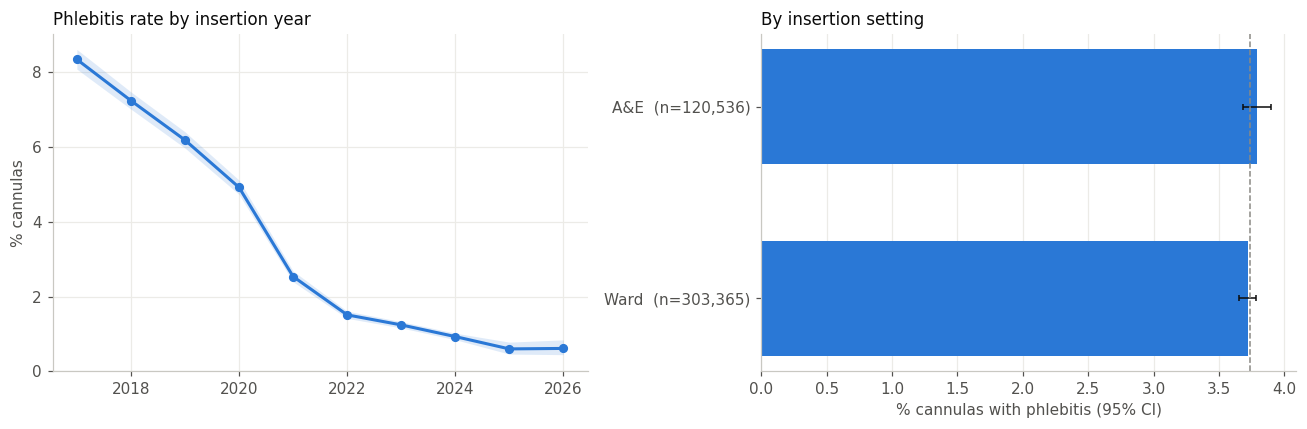

,n,events,rate
year,,,
2017,42247,3527,0.083485
2018,48753,3532,0.072447
2019,47164,2919,0.061890
2020,49127,2418,0.049219
2021,45753,1160,0.025354
2022,61662,930,0.015082
2023,67910,842,0.012399
2024,46170,428,0.009270
2025,9044,54,0.005971


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
yr = rate_table(cohort, 'year').loc[2017:]
axes[0].plot(yr.index, yr.rate * 100, color=BLUE, lw=2, marker='o', ms=5)
axes[0].fill_between(yr.index, yr.lo * 100, yr.hi * 100, color=BLUE, alpha=0.15, lw=0)
axes[0].set_title('Phlebitis rate by insertion year', loc='left', fontsize=11, color=INK); axes[0].set_ylabel('% cannulas')
axes[0].set_ylim(0)
rate_plot(cohort, 'setting', 'By insertion setting', ax=axes[1])
plt.tight_layout(); plt.show()
yr[['n', 'events', 'rate']]

### 6b. Cannula factors

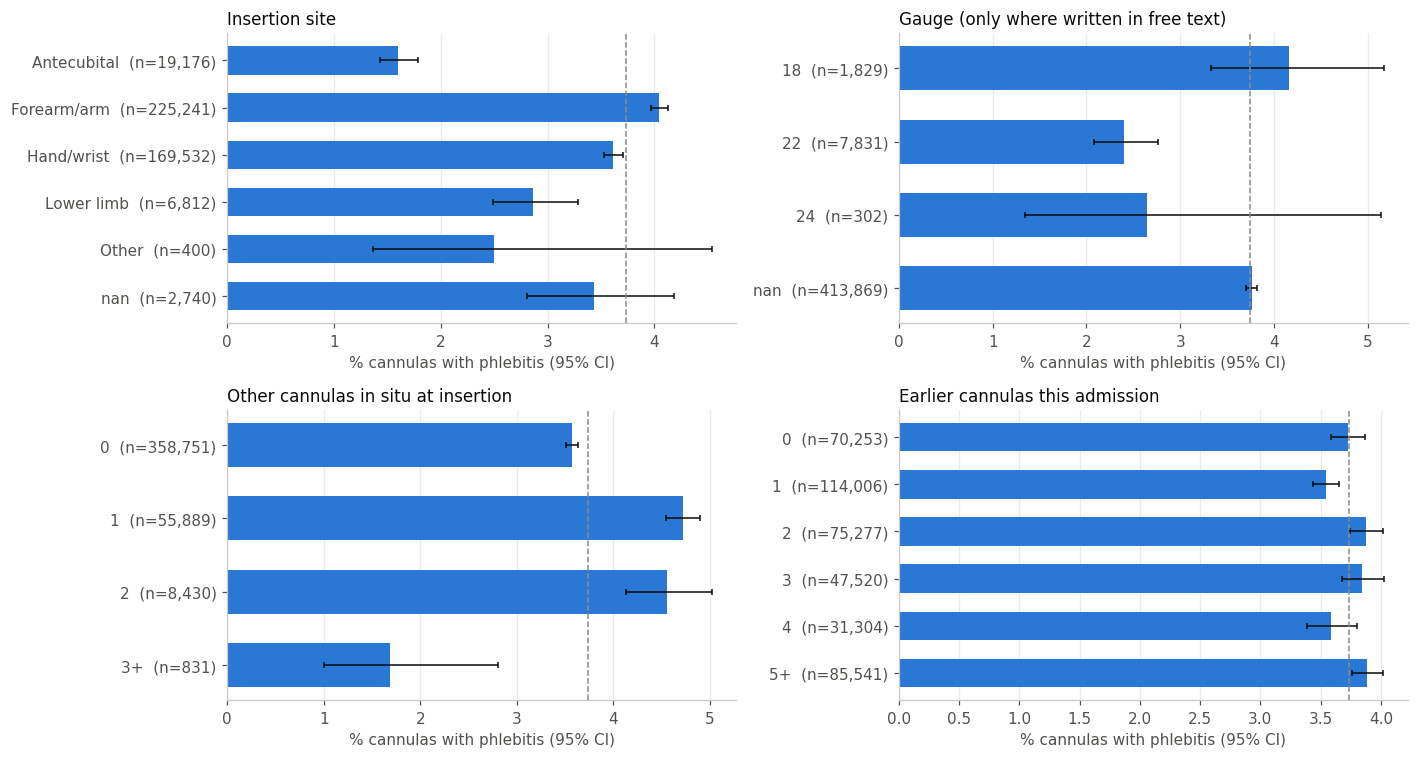

Gauge parsed for 2.4% of cannulas


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
rate_plot(cohort, 'site_insert', 'Insertion site', ax=axes[0, 0])
rate_plot(cohort, 'gauge', 'Gauge (only where written in free text)', ax=axes[0, 1], min_n=100)
cohort['concurrent_cat'] = cohort.concurrent_lines.clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'})
rate_plot(cohort, 'concurrent_cat', 'Other cannulas in situ at insertion', ['0', '1', '2', '3+'], ax=axes[1, 0])
cohort['prior_cat'] = cohort.prior_cannulas_adm.clip(upper=5).map(lambda v: f'{v:.0f}' if v < 5 else '5+')
rate_plot(cohort, 'prior_cat', 'Earlier cannulas this admission', ['0', '1', '2', '3', '4', '5+'], ax=axes[1, 1])
plt.tight_layout(); plt.show()
print('Gauge parsed for', f'{cohort.gauge.notna().mean():.1%}', 'of cannulas')

### 6c. Patient factors

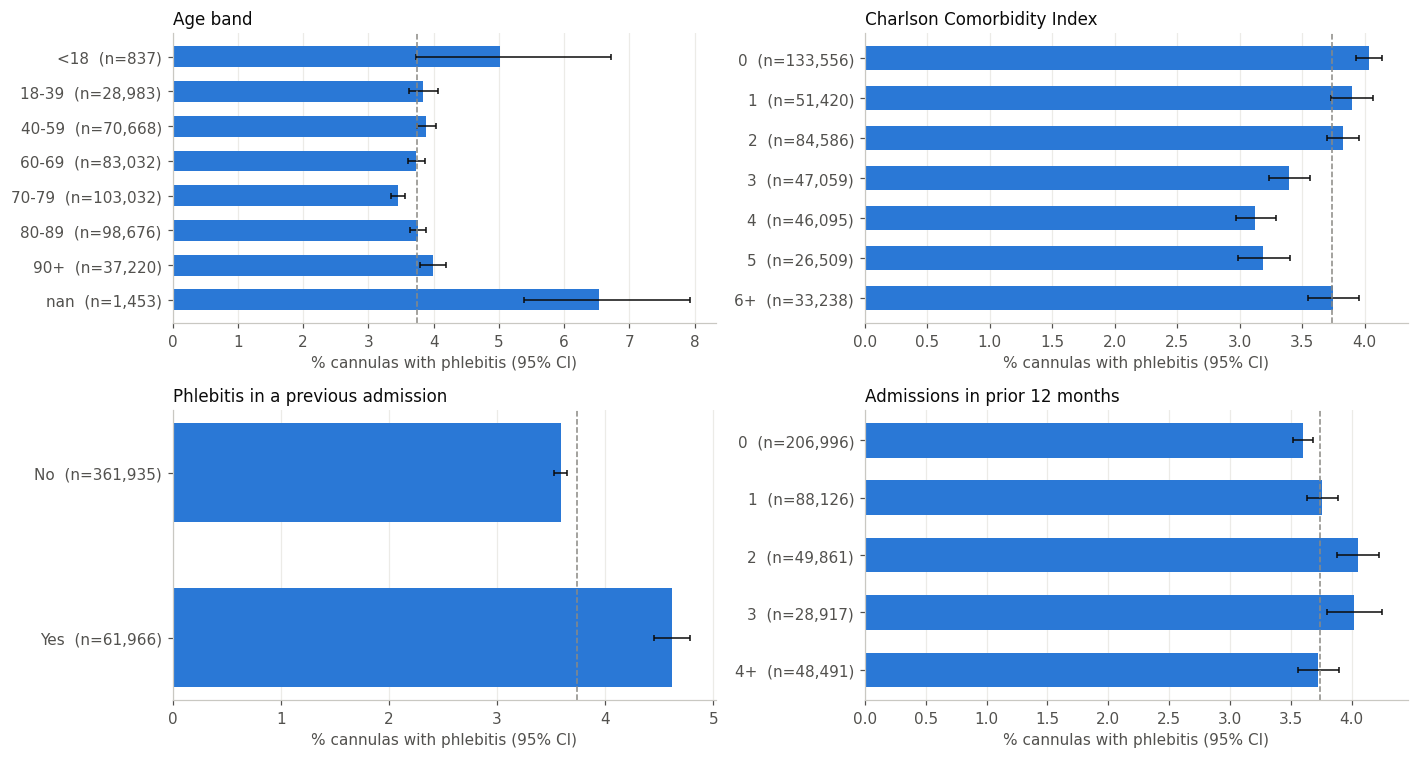

In [13]:
cohort['age_band'] = pd.cut(cohort.age, [0, 18, 40, 60, 70, 80, 90, 200], right=False,
                            labels=['<18', '18-39', '40-59', '60-69', '70-79', '80-89', '90+'])
cohort['cci_cat'] = cohort.cci.clip(upper=6).map(lambda v: np.nan if pd.isna(v) else (f'{v:.0f}' if v < 6 else '6+'))
cohort['hx_cat'] = np.where(cohort.prior_phleb_hx > 0, 'Yes', 'No')
cohort['adm12_cat'] = cohort.adm_12mths.clip(upper=4).map(lambda v: np.nan if pd.isna(v) else (f'{v:.0f}' if v < 4 else '4+'))
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
rate_plot(cohort, 'age_band', 'Age band', ax=axes[0, 0])
rate_plot(cohort, 'cci_cat', 'Charlson Comorbidity Index', ['0', '1', '2', '3', '4', '5', '6+'], ax=axes[0, 1])
rate_plot(cohort, 'hx_cat', 'Phlebitis in a previous admission', ax=axes[1, 0])
rate_plot(cohort, 'adm12_cat', 'Admissions in prior 12 months', ['0', '1', '2', '3', '4+'], ax=axes[1, 1])
plt.tight_layout(); plt.show()

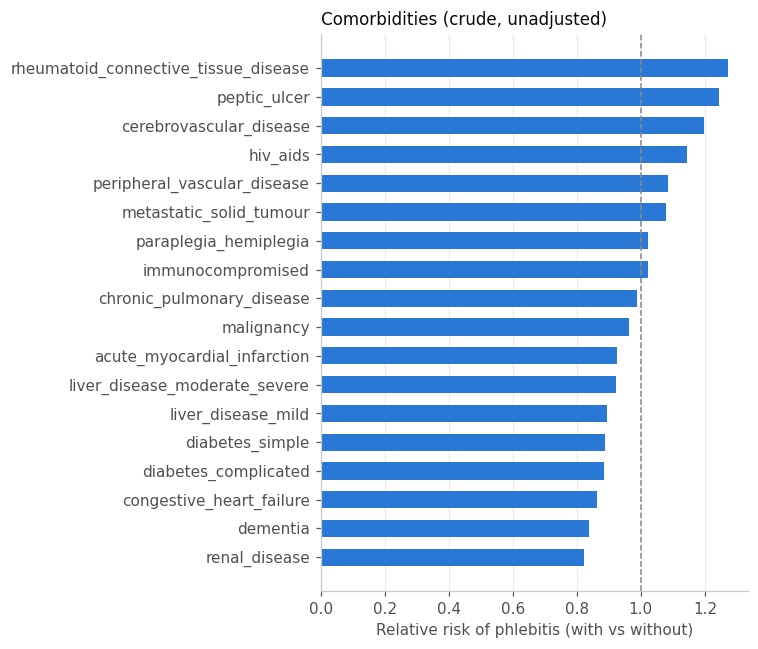

,condition,n_with,rate_with,rate_without,RR
3,rheumatoid_connective_tissue_disease,"2,028",4.73%,3.72%,1.27
7,peptic_ulcer,"5,734",4.62%,3.72%,1.24
1,cerebrovascular_disease,"25,153",4.41%,3.69%,1.20
16,hiv_aids,"1,359",4.27%,3.73%,1.15
8,peripheral_vascular_disease,"22,456",4.03%,3.71%,1.08
14,metastatic_solid_tumour,"19,010",4.00%,3.72%,1.08
12,paraplegia_hemiplegia,"17,468",3.81%,3.73%,1.02
17,immunocompromised,"5,279",3.81%,3.73%,1.02
9,chronic_pulmonary_disease,"13,927",3.68%,3.73%,0.99
10,malignancy,"20,070",3.59%,3.74%,0.96


In [14]:
# Individual comorbidities: rate with vs without, sorted by relative risk
rows = []
for c in [c.lower() for c in comorb]:
    s = cohort.groupby(c).phlebitis.agg(['size', 'mean'])
    if 1 in s.index and 0 in s.index:
        rows.append({'condition': c, 'n_with': int(s.loc[1, 'size']), 'rate_with': s.loc[1, 'mean'],
                     'rate_without': s.loc[0, 'mean'], 'RR': s.loc[1, 'mean'] / s.loc[0, 'mean']})
cm = pd.DataFrame(rows).sort_values('RR')
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(cm.condition, cm.RR, color=BLUE, height=0.6)
ax.axvline(1, color=GREY, lw=1, ls='--')
ax.set_xlabel('Relative risk of phlebitis (with vs without)'); ax.grid(axis='y', visible=False)
ax.set_title('Comorbidities (crude, unadjusted)', loc='left', fontsize=11, color=INK)
plt.tight_layout(); plt.show()
cm.sort_values('RR', ascending=False).style.format({'rate_with': '{:.2%}', 'rate_without': '{:.2%}', 'RR': '{:.2f}', 'n_with': '{:,}'})

### 6d. Skin & mobility (ward admissions with a nursing assessment)

Skin assessment available: 99.6% of cohort; done before insertion: 90.7%
Hours from skin assessment to insertion (quantiles):
{0.05: -1.0, 0.25: 17.6, 0.5: 67.4, 0.75: 178.5, 0.95: 644.0}


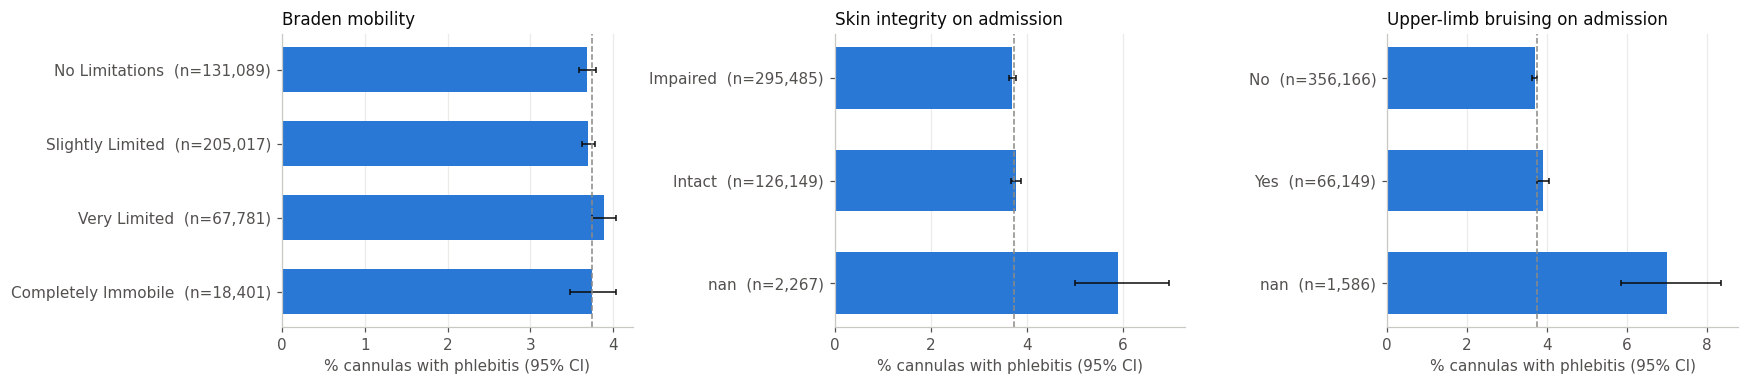

In [15]:
print(f"Skin assessment available: {cohort.skin_t.notna().mean():.1%} of cohort; "
      f"done before insertion: {(cohort.hrs_skin_to_insert >= 0).mean():.1%}")
print('Hours from skin assessment to insertion (quantiles):')
print(cohort.hrs_skin_to_insert.quantile([.05, .25, .5, .75, .95]).round(1).to_dict())
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
rate_plot(cohort, 'mobility', 'Braden mobility',
          ['No Limitations', 'Slightly Limited', 'Very Limited', 'Completely Immobile'], ax=axes[0])
rate_plot(cohort, 'skin_integrity', 'Skin integrity on admission', ax=axes[1])
cohort['bruise_cat'] = np.where(cohort.bruise_upper_limb.fillna(0).eq(1), 'Yes', np.where(cohort.skin_t.notna(), 'No', None))
rate_plot(cohort, 'bruise_cat', 'Upper-limb bruising on admission', ax=axes[2])
plt.tight_layout(); plt.show()

### 6e. Ward variation
Large between-ward differences may reflect **case-mix *and* documentation practice**. Consider ward as a random effect or a stratification factor rather than a fixed predictor.

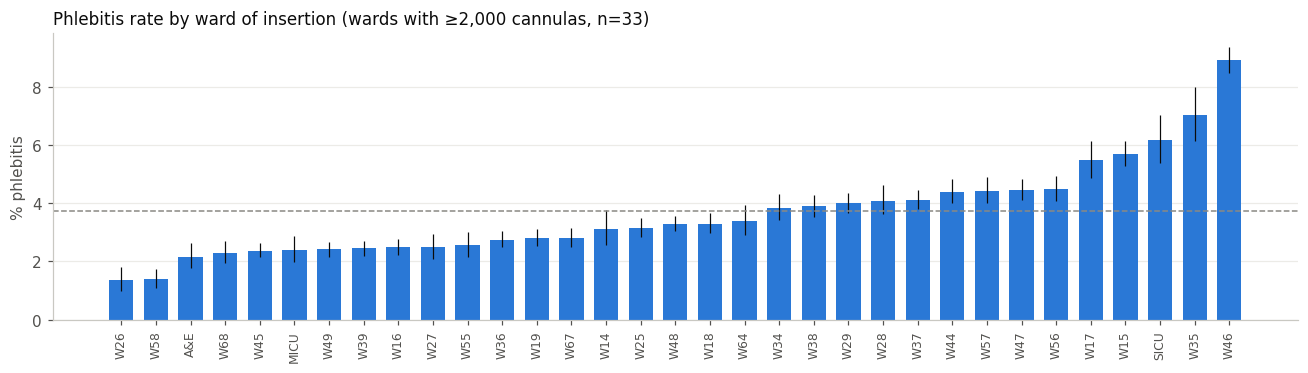

In [16]:
w = rate_table(cohort[cohort.setting == 'Ward'], 'ward_insert', min_n=2000).sort_values('rate')
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(w.index, w.rate * 100, color=BLUE, width=0.7)
ax.errorbar(w.index, w.rate * 100, yerr=[(w.rate - w.lo) * 100, (w.hi - w.rate) * 100], fmt='none', ecolor=INK, lw=0.8)
ax.axhline(base * 100, color=GREY, lw=1, ls='--')
ax.set_ylabel('% phlebitis'); ax.tick_params(axis='x', rotation=90, labelsize=8); ax.grid(axis='x', visible=False)
ax.set_title(f'Phlebitis rate by ward of insertion (wards with ≥2,000 cannulas, n={len(w)})', loc='left', fontsize=11, color=INK)
plt.tight_layout(); plt.show()

### 6f. Dwell time — **not a predictor at insertion**
Longer dwell means more exposure, and phlebitis also *ends* the dwell, so this is shown for understanding only. If the score is later re-run daily, rate per catheter-day becomes relevant.

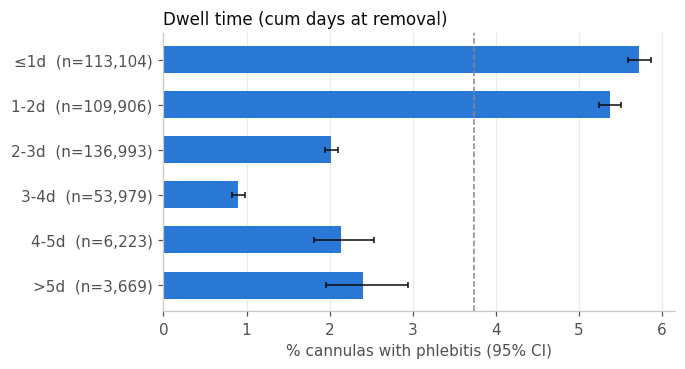

Incidence: 19.3 phlebitis per 1,000 catheter-days


In [17]:
cohort['dwell_cat'] = pd.cut(cohort.dwell_days, [-0.01, 1, 2, 3, 4, 5, 100], labels=['≤1d', '1-2d', '2-3d', '3-4d', '4-5d', '>5d'])
g = rate_plot(cohort, 'dwell_cat', 'Dwell time (cum days at removal)')
plt.show()
d = cohort.dropna(subset=['dwell_days'])
print(f"Incidence: {1000 * d.phlebitis.sum() / d.dwell_days.sum():.1f} phlebitis per 1,000 catheter-days")

### 6g. Outcome definition check — removals coded "Others" with a single sign
These are not counted as phlebitis (definition needs ≥2 signs), but may be under-ascertained cases. Worth confirming with the IPC team, and possibly running a sensitivity analysis.

In [18]:
print(f"Cohort: phlebitis={cohort.phlebitis.sum():,}, possible (1 sign, coded Others)={cohort.possible_phlebitis.sum():,}")
cohort.loc[cohort.possible_phlebitis == 1, 'removal_text'].str.lower().value_counts().head(12)

Cohort: phlebitis=15,847, possible (1 sign, coded Others)=24,528


removal_text
removed - others swelling             7323
removed - others swollen              3221
removed - others pain                 2605
removed - others redness              1604
removed - others swelling noted        434
removed - others c/o pain              370
removed - others slight swelling       314
removed - others swelling seen         194
removed - others redness seen          181
removed - others swelling observed     147
removed - others slight redness        146
removed - others redness noted         135
Name: count, dtype: int64

### 6h. The phlebitis definition changed in late 2020
The removal code switched from *"Phlebitis (Redness/Swelling/Pain)"* (any sign) to *"Phlebitis (Any 2 signs)"*. At the same time the single-sign "Others" removals rose. **Much of the 8% → 1% drop is a stricter definition, not only better care.**

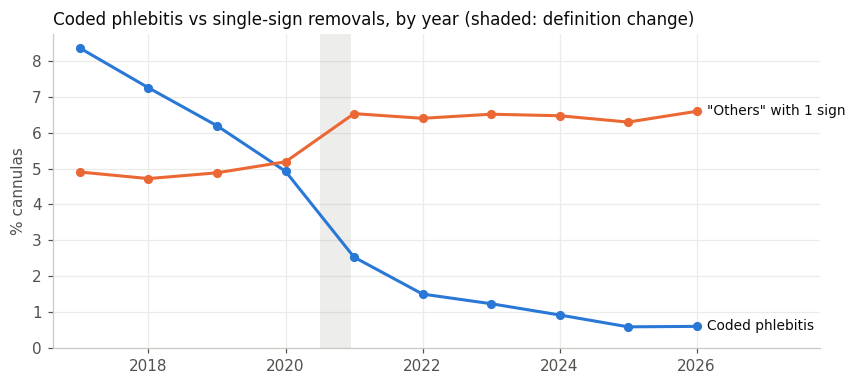

,n,pct_phlebitis,pct_possible,new: any 2 signs,old: any sign
year,,,,,
2017,"42,247",8.35%,4.90%,0.000000,3506.000000
2018,"48,753",7.24%,4.72%,0.000000,3517.000000
2019,"47,164",6.19%,4.88%,0.000000,2909.000000
2020,"49,127",4.92%,5.19%,144.000000,2269.000000
2021,"45,753",2.54%,6.53%,1154.000000,0.000000
2022,"61,662",1.51%,6.40%,928.000000,0.000000
2023,"67,910",1.24%,6.51%,841.000000,0.000000
2024,"46,170",0.93%,6.47%,425.000000,0.000000
2025,"9,044",0.60%,6.29%,64.000000,0.000000


In [19]:
cohort['wording'] = np.select([cohort.removal_text.str.contains('Redness/Swelling/Pain', na=False, regex=False),
                               cohort.removal_text.str.contains('Any 2 signs', na=False, regex=False)],
                              ['old: any sign', 'new: any 2 signs'], None)
defn = cohort.groupby('year').agg(n=('phlebitis', 'size'), pct_phlebitis=('phlebitis', 'mean'),
                                  pct_possible=('possible_phlebitis', 'mean'))
defn = defn.join(pd.crosstab(cohort.year, cohort.wording)).loc[2017:]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(defn.index, defn.pct_phlebitis * 100, color=BLUE, lw=2, marker='o', ms=5)
ax.plot(defn.index, defn.pct_possible * 100, color='#eb6834', lw=2, marker='o', ms=5)
ax.text(defn.index[-1] + 0.15, defn.pct_phlebitis.iloc[-1] * 100, 'Coded phlebitis', color=INK, va='center', fontsize=9)
ax.text(defn.index[-1] + 0.15, defn.pct_possible.iloc[-1] * 100, '"Others" with 1 sign', color=INK, va='center', fontsize=9)
ax.axvspan(2020.5, 2020.95, color=GREY, alpha=0.15, lw=0)
ax.set_xlim(2016.6, 2027.8); ax.set_ylim(0); ax.set_ylabel('% cannulas')
ax.set_title('Coded phlebitis vs single-sign removals, by year (shaded: definition change)', loc='left', fontsize=11, color=INK)
plt.tight_layout(); plt.show()
defn.style.format({'pct_phlebitis': '{:.2%}', 'pct_possible': '{:.2%}', 'n': '{:,}'})

## 7. Summary & next steps

**Columns to exclude as predictors (leakage / post-insertion info):** `Event`, `RemovedReason`, `Phlebitis`, `Episode`, `Cum Days`/dwell, `max_set`, `set_category` (whole-admission count, known only at discharge), `DischargeDtm`, `removal_text`.

**Candidate predictors available at insertion:** age, CCI + individual comorbidities, immunocompromised, admissions in prior 12m, prior phlebitis history, site, side, setting (A&E/ward), ward, concurrent lines, prior cannulas this admission, skin integrity / bruising / mobility (when assessed before insertion), year (for drift).

**Not in this extract (deck lists them):** gender, BMI, IV medications / osmolarity / infusion type, blood products, infusion pump, concurrent infection. Medication-related variables are among the strongest known phlebitis risk factors, so they are worth requesting.

**What the crude EDA shows** (unadjusted, confounded by year and ward)
- Calendar time dominates: 8.3% (2017) → 0.6% (2025), driven largely by the **late-2020 definition change** (6h).
- Large **between-ward variation** (~1.4% to ~9%).
- Modest signals: ≥1 other cannula in situ at insertion, phlebitis in a previous admission (~4.6% vs 3.6%), forearm/arm site; antecubital is *lower* (1.6%), opposite to the dictionary's note.
- Little crude signal from age, CCI, individual comorbidities, mobility or skin integrity.
- Short dwell has the *highest* rate: reverse causation (phlebitis ends the dwell), so dwell is not a predictor.

**Questions for the clinical team**
1. Confirm the definition change date and that "Any 2 signs" is the target outcome.
2. Should "Removed – Others" with swelling/pain/redness (≈ 6% of cannulas from 2021 onward) count? Some list 2 signs and arguably meet the definition.
3. Can gender, BMI and IV medication / infusate data be added?

**Modelling implications**
- **Restrict to 2021+** (current definition, rate ~1–2%, matching the brief) or include a definition-era term; then use a **temporal split** (e.g. train 2021–2023, validate 2024+). Report **calibration** + AUPRC, not just AUROC.
- Plenty of events (EPV ≫ 20): heavy resampling (SMOTE etc.) is unnecessary and distorts calibration. Prefer class weights or just threshold choice on predicted risk.
- Multiple cannulas per patient/admission → **cluster-aware** CV / standard errors (group by patient).
- The binary 1/0 alert = predicted risk ≥ threshold chosen with nurses for an acceptable alerts-per-ward-per-day workload.